# pyDySP Demo

This notebook gives a compact tour of the core **pyDySP** features using synthetic multi‑channel time histories. We go from signal generation and `Channel` / `Test` construction, to basic processing and plotting, cross‑channel analysis, and simple CSV I/O.

For analysis across a whole series of tests, see the [pyDySP Campaign Demo](campaign_demo.ipynb).

In [1]:
# Imports and version
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import scipy as sp

import pydysp

print("pyDySP version:", pydysp.__version__)

pyDySP version: 0.2.2


## Artificial data generation

For this example, we first build a small set of synthetic signals (pulses, delayed copies, a noise‑only channel, and the response of an SDOF), which we will use throughout the demo. In practice, we would use experimental data.

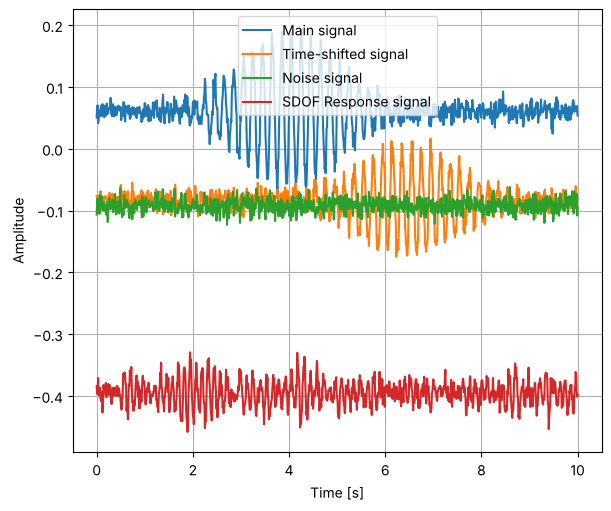

In [2]:
# Generate synthetic multi‑channel signals (time vector and individual components)
t = np.linspace(0, 10, 1001)

# Empty signal list
signals = []
legends = []

# Gaussian modulated sine wave
a0 = 0.5 / 4  # amplitude of the sine wave (with calibration factor 4.0)
f0 = 5  # frequency of the sine wave
t0 = 4  # center of the Gaussian envelope
dur = 6  # duration of the Gaussian envelope
sigma = dur / 2 / 3  # convert duration to standard deviation (+- 3 sigma)

# Time shifted copy
dt = 2.5  # time shift
a_ratio = 0.7  # amplitude ratio

# SDOF properties
ksi = 0.05
f_sdof = 8
omega = 2 * np.pi * f_sdof

# Offset and noise level
offset = 0.2  # vertical offset (random)
noise = 0.01  # noise level (random)

# Use modern RNG API for reproducibility
rng = np.random.default_rng(42)

# Generate main signal (gaussian-modulated sine wave)
signal = a0 * np.sin(2 * np.pi * f0 * t) * np.exp(-((t - t0) ** 2) / (2 * sigma**2))
signals.append(
    signal + offset * rng.standard_normal() + noise * rng.standard_normal(len(t))
)
legends.append("Main signal")

# Generate time-shifted signal
signal = (
    a_ratio
    * a0
    * np.sin(2 * np.pi * f0 * (t - dt))
    * np.exp(-((t - t0 - dt) ** 2) / (2 * sigma**2))
)
signals.append(
    signal + offset * rng.standard_normal() + noise * rng.standard_normal(len(t))
)
legends.append("Time-shifted signal")

# Generate noise signal
signal_noise = noise * rng.standard_normal(len(t))  # use as base for SDOF input
signals.append(signal_noise + offset * rng.standard_normal())
legends.append("Noise signal")

# Generate SDOF Response signal
a_in = sp.interpolate.interp1d(t, signal_noise)  # use noise from above


def sdof_ode(t, y):
    u, v = y
    a = a_in(t) - 2.0 * ksi * omega * v - (omega**2) * u
    return [v, a]


sol = sp.integrate.solve_ivp(
    sdof_ode, (t[0], t[-1]), [0.0, 0.0], t_eval=t, method="RK45"
)
u = sol.y[0]
v = sol.y[1]
signal = -2.0 * ksi * omega * v - (omega**2) * u
signals.append(
    signal + offset * rng.standard_normal() + noise * rng.standard_normal(len(t))
)
legends.append("SDOF Response signal")

# Plot signals
signals = np.array(signals).T
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.plot(t, signals)
ax.legend(legends)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude")
ax.grid(True)
plt.show()

## Building `Channel` and `Test` objects

`Channel` and `Test` wrap raw NumPy arrays with metadata (names, units, sampling interval) and provide the main API for later processing and plotting.

In [3]:
# Create pyDySP Channels from the synthetic signals
n_channels = signals.shape[1]
channels = [
    pydysp.Channel(
        data=signals[:, i],
        time=t,
        name_user=f"Channel {i+1}",
        description_long=legends[i],
        quantity="acceleration",
        units="g",
        tags={"synthetic"},
        calibration_factor=4.0,
    )
    for i in range(n_channels)
]

# Wrap channels into a Test for experiment‑level operations
# Create pyDySP Test
test = pydysp.Test.from_channels(
    name="Demo test",
    channels=channels,
    description="Artificial data for demonstration purposes",
)

# Print test info
print(test.info())

Test: Demo test
---------------
Description: Artificial data for demonstration purposes
Channels: 4
Timesteps: 1001
Duration: 10 s
Sampling: dt=0.01 s, fs=100 Hz

|   idx | name_user   | name_input   | quantity     | units   | description          | tags                     |   calibration_factor |
|-------|-------------|--------------|--------------|---------|----------------------|--------------------------|----------------------|
|     0 | -           | Channel 1    | acceleration | g       | Main signal          | q:acceleration,synthetic |                    4 |
|     1 | -           | Channel 2    | acceleration | g       | Time-shifted signal  | q:acceleration,synthetic |                    4 |
|     2 | -           | Channel 3    | acceleration | g       | Noise signal         | q:acceleration,synthetic |                    4 |
|     3 | -           | Channel 4    | acceleration | g       | SDOF Response signal | q:acceleration,synthetic |                    4 |


## Working with a single `Channel`

Single‑channel operations are useful for quick inspection, basic processing and plotting before moving to full `Test`‑level workflows.

### Calling a channel

Accessing a single `Channel` from the `Test`.

In [4]:
# Different ways to select a channel
ch1a = test[0]
ch1b = test.channel[0]
ch1c = test.channels[0]
ch1d = test["Channel 1"]

# Confirm they are the same
print(ch1a.name_user)
print(ch1b.name_user)
print(ch1c.name_user)
print(ch1d.name_user)

Channel 1
Channel 1
Channel 1
Channel 1


### Processing channel data

Here we apply simple pre‑processing (detrend, filtering, baseline correction, trimming). Processing is lazy: it is only applied when the data are accessed.

In [5]:
# Processing channel data
ch1 = test[0].drift_corrected(points=20).filtered(btype="lowpass", fc=20, order=2)

# Print processed channel info
print(ch1.info())

Channel: Channel 1
------------------
Length: 1001 samples
Sampling frequency: fs = 100 Hz
Timestep: dt = 0.01 s
Start time: t0 = 0.0 s

Physical meaning & calibration:
  Quantity: acceleration
  Units: g
  Calibration factor: 4.0 g/raw

Naming / labels:
  User name: Channel 1
  Legend label: Channel 1
  Axis label: Channel 1 [g]
  Description: Main signal

Tags:
  drift_corrected
  filtered
  q:acceleration
  synthetic

Processing:
  Drift params: {'points': 20}
  Filter params: {'btype': 'lowpass', 'fc': 20, 'order': 2}
  Notes:
    - Drift params set: {'points': 20}
    - Filter params set: {'btype': 'lowpass', 'fc': 20, 'order': 2}


Accessing the underlying NumPy arrays.

In [6]:
# Get time and acceleration
time, accel = ch1.xy()

# Print
print("time:", time)
print("accel:", accel)

time: [ 0.    0.01  0.02 ...  9.98  9.99 10.  ]
accel: [-0.03927162  0.00556491  0.00419614 ...  0.0177404   0.00225336
 -0.02686235]


### Plotting

Quick‑look plots of the time history, Fourier spectrum, power spectral density, and response spectrum, with optional peak annotations.

Timehistory Peak: (4.25, 0.5111310505851981)
Fourier Peak: (4.98046875, 61.682209953784714)


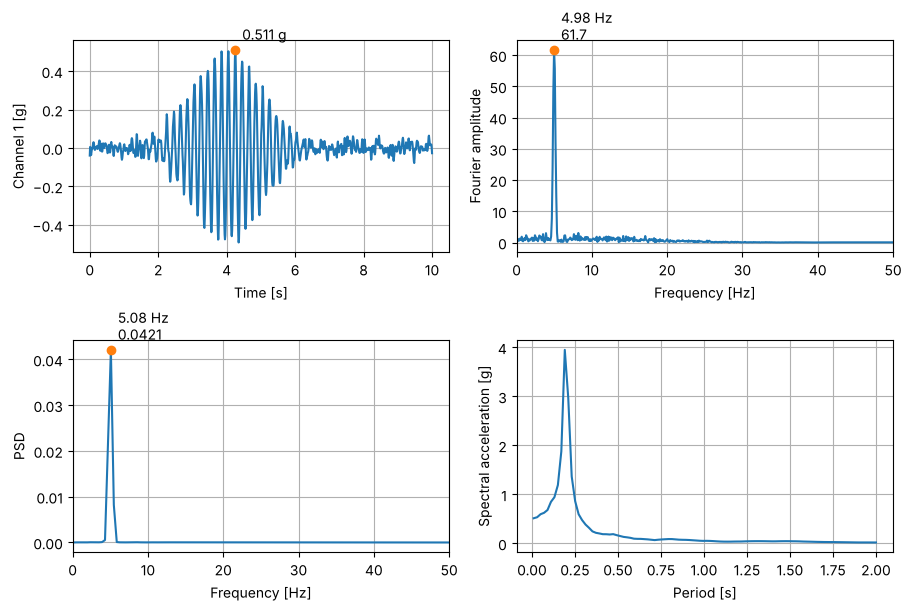

In [7]:
# Plot channel data
fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout="constrained")

ch1.plot(ax=axes[0, 0])
ch1.plot_fourier(ax=axes[0, 1])
ch1.plot_psd(ax=axes[1, 0])
ch1.plot_response_spectrum(periods=np.linspace(0.01, 2.0, 100), ax=axes[1, 1])

# Helper function for peak annotation
pydysp.annotate_peak(channel=ch1, ax=axes[0, 0], peak="abs")
pydysp.annotate_peak(channel=ch1, ax=axes[0, 1], plot="fourier")
pydysp.annotate_peak(channel=ch1, ax=axes[1, 0], plot="psd")

# Printing relevant peaks
print("Timehistory Peak:", ch1.max_abs())
print("Fourier Peak:", ch1.fourier_peak())

### Arias intensity & automatic trimming

Demonstrates built‑in Arias intensity calculation and the helper for automatically trimming strong‑motion windows around the main signal.

Original duration: 10.0
Trimmed duration:  4.01


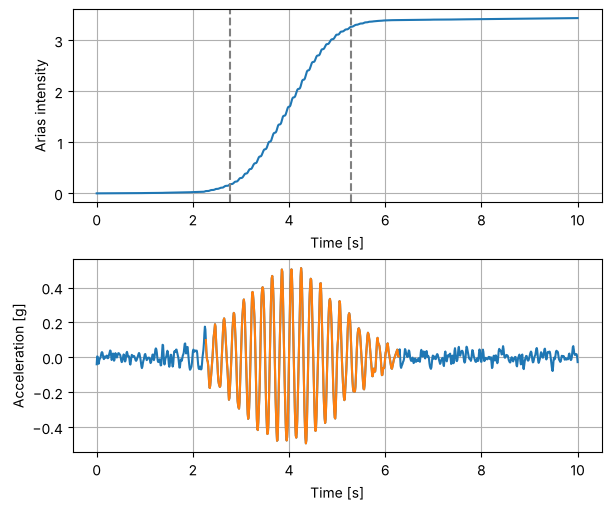

In [8]:
# Trim the strong-motion window using Arias intensity
ch1_trimmed = ch1.trim_by_arias(
    lower=0.05, upper=0.95, buffer_before=0.5, buffer_after=1
)

# Plot original and trimmed signals
fig, axes = plt.subplots(2, 1, figsize=(6, 5), layout="constrained")
ch1.plot_arias(ax=axes[0], show_window=True)
ch1.plot(ax=axes[1])
ch1_trimmed.plot(ax=axes[1], include_kind=True)

# Print Arias Intensity and durations

print("Original duration:", ch1.duration)
print("Trimmed duration: ", ch1_trimmed.duration)

## Working at `Test` level

A `Test` groups several `Channel` instances from the same experiment and exposes batch operations and cross‑channel analysis.

### Batch Processing

Apply the same processing chain to many channels at once, keeping the workflow reproducible.

In [9]:
# Batch‑process all channels in the Test
test = test.drift_corrected(points=200).filtered(btype="lowpass", fc=20, order=2)

test_trimmed = test.trimmed_by_arias(
    ref="Channel 1", lower=0.05, upper=0.95, buffer_before=0.5, buffer_after=1
)

print("Original duration:", test.duration)
print("Trimmed duration:  ", test_trimmed.duration)

Original duration: 10.0
Trimmed duration:   4.01


### Batch Plotting

Produce consistent plots for one or more channels with shared axes and layout.

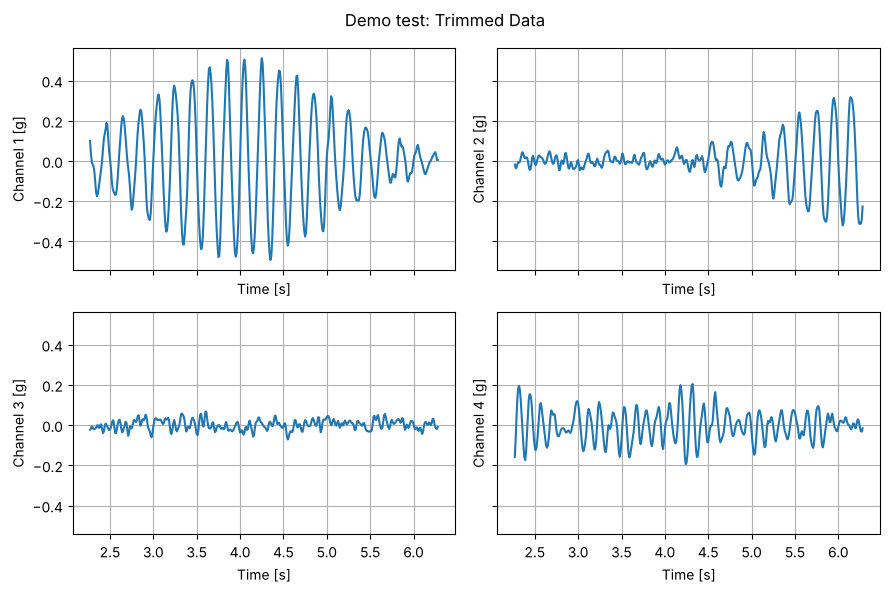

In [10]:
# Quick overview plot of selected channels
fig, ax = test_trimmed.plot_channels(
    selector=[
        0,
        1,
        2,
        "Channel 4",
    ],  # use numeric indices, names, tags, or None for all
    ncols=2,
    plot_type="timehistory",
    title_suffix="Trimmed Data",
)
fig.set_size_inches(9, 6)

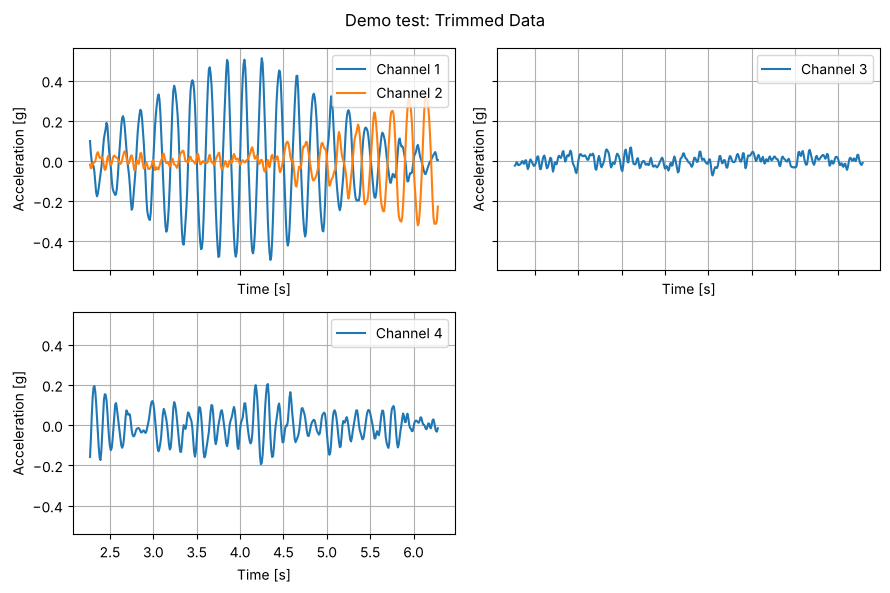

In [11]:
# Advanced grid plot layouts
fig, ax = test_trimmed.plot_grid(
    layout=[[(0, 1), 2], [3]],  # use [] for grid layout, () for merged plots
    plot_type="timehistory",
    title_suffix="Trimmed Data",
)
fig.set_size_inches(9, 6)

## Cross-channel analysis

Compute frequency‑domain relationships between channels (cross‑spectra, transfer functions, coherence).

sdypy not installed; skipping EMA example.


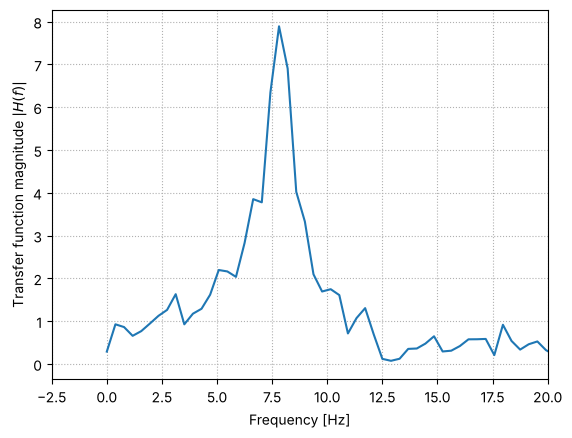

In [12]:
# Transfer function between a reference (x) and a response (y) channel
ax = test.plot_transfer_function(
    x="Channel 3", y="Channel 4", kind="H1", tf_kwargs={"nperseg": 256}
)
ax.set_xscale("linear")
ax.set_xlim(right=20)

# Create model for Experimental Modal Analysis (sdypy-EMA)
try:
    ema_model = test.ema_model(
        input="Channel 3",
        outputs=["Channel 4"],
        kind="H1",
        lower=1.0,
        upper=20.0,
    )
except ImportError:
    print("sdypy not installed; skipping EMA example.")

In [13]:
# Time delay between a transmitter (x) and a receiver (y)
delay = test.time_delay(x="Channel 1", y="Channel 2")
print("Estimated time delay [s]:", delay)

Estimated time delay [s]: 2.5


### Channel health report

Run simple diagnostics to flag channels that are flat, noise‑only, or otherwise suspicious.

In [14]:
# Basic channel health diagnostics for all channels in the Test
print(test.channel_health(fraction_for_event=0.2))

|   idx | name      |   peak |    rms |   crest |   t_start |   t_end |   dur | rms_pre   | snr_pre   | status        |
|-------|-----------|--------|--------|---------|-----------|---------|-------|-----------|-----------|---------------|
|     0 | Channel 1 |  0.511 |  0.149 |    3.42 |      2.24 |    5.84 |   3.6 | 0.0307    | 7.99      | ok            |
|     1 | Channel 2 |   0.36 |  0.107 |    3.37 |      2.12 |    8.44 |  6.32 | 0.0256    | 5.21      | ok            |
|     2 | Channel 3 | 0.0747 | 0.0239 |    3.13 |         0 |    9.98 |  9.98 | -         | -         | weak response |
|     3 | Channel 4 |   0.23 | 0.0724 |    3.18 |      0.11 |    9.97 |  9.86 | 0.0258    | 2.82      | weak response |


## Saving to `csv` and reloading

Export processed data and metadata to CSV for archiving or sharing, and show how to reconstruct a `Test` object from disk. The files go into a temporary folder here, so running the notebook leaves nothing behind.

In [15]:
# Save processed data/metadata to CSV files in a temporary folder
tmpdir = tempfile.TemporaryDirectory()
data_file = os.path.join(tmpdir.name, "demo_data.csv")
info_file = os.path.join(tmpdir.name, "demo_channel_info.csv")
test.to_csv(filename=data_file, overwrite=True)
test.channel_info_to_csv(filename=info_file, overwrite=True)

# Reconstruct Test from CSV
test_reloaded = pydysp.Test.from_csv(
    data_file, name="ProcessedFromCSV"
).with_channel_info_from_csv(
    info_file,
)

# Print reloaded test and channel info
print(test_reloaded.info())
print("\n" + "-" * 80 + "\n")
print(test_reloaded.channel[1].info())

# Remove the temporary folder
tmpdir.cleanup()

Test: ProcessedFromCSV
----------------------
Source file: /tmp/tmpkj5nl6m6/demo_data.csv
Channels: 4
Timesteps: 1001
Duration: 10 s
Sampling: dt=0.01 s, fs=100 Hz

Tags:
  csv

Metadata:
  csv_header: ['Time', 'Channel 1 [g]', 'Channel 2 [g]', 'Channel 3 [g]', 'Channel 4 [g]']
  csv_n_samples: 1001
  csv_n_channels: 4

|   idx | name_user     | name_input   | quantity     | units   | description          | tags                                              |   calibration_factor |
|-------|---------------|--------------|--------------|---------|----------------------|---------------------------------------------------|----------------------|
|     0 | Channel 1 [g] | Channel 1    | acceleration | g       | Main signal          | drift_corrected,filtered,q:acceleration,synthetic |                    4 |
|     1 | Channel 2 [g] | Channel 2    | acceleration | g       | Time-shifted signal  | drift_corrected,filtered,q:acceleration,synthetic |                    4 |
|     2 | Channel 3 [g

## Next steps

- Load your own data with `Test.from_sofsi_mat`, `Test.from_equals_mat` or `Test.from_csv`, and keep channel metadata in a channel-info CSV.
- For many tests from one campaign (selection by tag and test number, values and transfer functions across tests), see the [pyDySP Campaign Demo](campaign_demo.ipynb).
- See the [documentation](https://pydysp.readthedocs.io/en/latest/) for the full API.